This notebook refits QUEST to random subsets of trials, and asks how the crowding vs. RSVP correlation changes with the noise ceiling, for all participants and for random subsets of 25 and 50 participants.

Input (from `extract_trials_level_response.ipynb`):
- `tidy_both_sessions_trials_level_response.csv`
- `tidy_both_sessions_staircases_quest_params.csv`

Steps:
1. Rebuild each staircase's QUEST posterior and check that the posterior mean matches EasyEyes' `questMeanAtEndOfTrialsLoop`.
2. For each number of trials k, randomly pick k trials (without replacement) from every staircase and refit QUEST. Repeat `n_draws` times. Within a draw, the subsets are nested across k.
3. For each pair (k crowding, k RSVP) and each draw: reliability of each task (split-half r, each raised to at least `rel_floor` = 0.01, then Spearman-Brown), noise ceiling = sqrt(rel_crowding * rel_rsvp), measured r, and corrected r = measured r / noise ceiling, capped at -1 and 1.
4. Repeat step 3 with `subset_sizes` (25 and 50) participants, chosen anew in each draw.
5. Plot the median and 68% band of -r against the noise ceiling, for 25, 50 and all participants, with the ranges where r should not be corrected marked by faint gray slanted lines. These ranges come from the closed-form rule of `plots_correlationPaper.ipynb` (eq. 6), applied to a smoothed version of the measured-r curve. Above each panel, heatmaps from `plots_correlationPaper.ipynb` show whether correcting r lowers its error, for a few values of measured r, the last at the right end of the curve.

Results are saved to `subsample_corr_crowding_rsvp.csv` (all participants) and `subsample_corr_crowding_rsvp_n<size>.csv`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

In [3]:
# settings
n_draws = 200
seed = 2026
quest_range = 5  # width (log units) of QUEST's grid of candidate thresholds; the jsQUEST default, validated below

# number of trials sampled from each staircase; np.inf = all trials
k_grid = {'crowding': [2, 4, 7, 8, 10, 12, 15, 18, 21, 25, 30, np.inf],  # letter trials (about 35 per staircase)
          'rsvp':     [2, 4, 6, 7, 9, 15, 21, 30, 40, 50, 60, np.inf]}  # single words (about 70 per staircase)

# staircases per participant, as columns of repeats.
# The order sets the split halves: first/last half = session 1 vs. session 2; odd/even = L8 vs. R8.
columns = {'crowding': ['crowding_R8_block1', 'crowding_L8_block1', 'crowding_R8_block2', 'crowding_L8_block2',
                        'crowding_R8_block3', 'crowding_L8_block3', 'crowding_R8_block4', 'crowding_L8_block4'],
           'rsvp': ['rsvp_foveal_block1', 'rsvp_foveal_block2']}

# split-half r below this (including negative r) is raised to it before computing reliability
rel_floor = 0.01

# numbers of participants for the smaller-sample panels
subset_sizes = [25, 50]

output_path = 'subsample_corr_crowding_rsvp.csv'

# font size of all text in the figures
font_size = 15
plt.rcParams.update({key: font_size for key in
                     ['font.size', 'axes.titlesize', 'axes.labelsize', 'xtick.labelsize', 'ytick.labelsize', 'legend.fontsize']})

# plot colors
#   light: 68% bands; dark: median lines
plot_colors = {'r_measured': {'light': '#9FBCA3', 'dark': '#507255'},
               'r_corrected': {'light': '#D1B3C2', 'dark': '#8E5572'}}
plot_colors = {'r_measured': {'light': '#F8C463', 'dark': '#AF7508'},
               'r_corrected': {'light': '#C19AB1', 'dark': '#59364A'}}
# ranges of the noise ceiling where r should not be corrected, marked by faint gray slanted lines.
#   'closed_form': where correcting does not lower the RMSE (eq. 6 of plots_correlationPaper), along the smoothed
#                  median curve of measured r (-r = rho * noise ceiling, rho fitted per panel); the plotted curve is not smoothed
#   'manual': the ranges set by hand in no_correction_ranges (also used by the original figure)
no_correction_method = 'closed_form'
# keys: number of participants ('all' = every participant); values: (start, end) ranges, None = edge of the plot
no_correction_ranges = {'all': [(None, 0.35), (0.9, None)],
                        50: [(None, 0.6), (0.85, None)],
                        25: [(None, None)]}
no_correction_color = '#EBEBEB'  # solid gray of the original figure
no_correction_hatch = '//'
no_correction_hatch_color = '#C8C8C8'

# heatmap insets above each panel (from plots_correlationPaper.ipynb): RMSE of corrected r over RMSE of measured r,
# for each of these measured -r, found where the median curve of measured -r first reaches it;
# 'end' = the right end of the curve (all trials), so its r differs a little between panels
inset_r = [0.1, 0.28, 'end']
inset_method = 'known'  # closed form (eqs. 4-6 in plots_correlationPaper), noise ceiling treated as known
inset_color_scale = 'log'
inset_labels = False  # title, tick marks, tick labels and axis labels of each heatmap

# Import data

In [4]:
trials = pd.read_csv('tidy_both_sessions_trials_level_response.csv')
staircases = pd.read_csv('tidy_both_sessions_staircases_quest_params.csv')
staircases = staircases[staircases['nTrials'] > 0].reset_index(drop=True)

# QUEST
Same computation as QuestCreate, QuestUpdate and QuestMean (Watson & Pelli, 1983, *Perception & Psychophysics* 33:113-120; jsQUEST in EasyEyes):
- Prior: Gaussian over log threshold, mean tGuess, SD tGuessSd, on a grid with step `grain`.
- Psychometric function (Weibull): P(correct) = delta*gamma + (1-delta) * (1 - (1-gamma) * exp(-10^(beta * (level - threshold + xThreshold)))). xThreshold makes P(correct) = pThreshold when level = threshold.
- Estimate: posterior mean.

Because the posterior is the prior times the likelihood of each response, the order of trials does not matter, so a random subset can be fit directly.

In [5]:
def quest_grid(st, quest_range=5):
    """Candidate thresholds (log units) and log prior, as in QuestCreate."""
    dim = int(2 * np.ceil(quest_range / st.grain / 2))
    x = np.arange(-dim // 2, dim // 2 + 1) * st.grain
    return st.tGuess + x, -0.5 * (x / st.tGuessSd) ** 2, dim


def quest_loglik(st, levels, responses, quest_range=5):
    """
    Log likelihood of each response (rows) at each candidate threshold (columns).
    As in QuestUpdate, the level is rounded to the grid, and level - threshold is limited to the table range.
    """
    t, _, dim = quest_grid(st, quest_range)
    xThreshold = np.log10(-np.log((1 - (st.pThreshold - st.delta * st.gamma) / (1 - st.delta)) / (1 - st.gamma))) / st.beta
    levels = st.tGuess + st.grain * np.round((np.asarray(levels) - st.tGuess) / st.grain)
    d = np.clip(levels[:, None] - t[None, :], -dim * st.grain, dim * st.grain)
    p = st.delta * st.gamma + (1 - st.delta) * (1 - (1 - st.gamma) * np.exp(-10 ** (st.beta * (d + xThreshold))))
    return np.where(np.asarray(responses)[:, None] == 1, np.log(p), np.log(1 - p))


def quest_mean(t, log_posterior):
    """Posterior mean (QuestMean). log_posterior can be 1-D, or 2-D with one row per draw."""
    w = np.exp(log_posterior - log_posterior.max(axis=-1, keepdims=True))
    return (w * t).sum(axis=-1) / w.sum(axis=-1)

In [6]:
# build the likelihood table of every staircase once
trials_by_staircase = dict(tuple(trials.groupby(['prolificID', 'conditionName'])))
quest_tables = {}
for st in staircases.itertuples():
    g = trials_by_staircase[(st.prolificID, st.conditionName)]
    t, log_prior, _ = quest_grid(st, quest_range)
    quest_tables[(st.prolificID, st.conditionName)] = (t, log_prior, quest_loglik(st, g['level'], g['response'], quest_range))

In [7]:
# validation: refit with all trials and compare with EasyEyes' final QUEST mean
staircases['refit_all_trials'] = [quest_mean(t, log_prior + L.sum(axis=0))
                                  for t, log_prior, L in (quest_tables[key] for key in zip(staircases['prolificID'], staircases['conditionName']))]
refit_error = (staircases['refit_all_trials'] - staircases['questMeanAtEnd']).abs()

print('Largest |refit - questMeanAtEndOfTrialsLoop| (log units):')
print(refit_error.groupby(staircases['taskName']).max())
assert refit_error.max() < 1e-3, 'Fatal: QUEST refit does not match EasyEyes'

Largest |refit - questMeanAtEndOfTrialsLoop| (log units):
taskName
acuity      0.000002
crowding    0.000002
rsvp        0.000010
dtype: float64


# Data cleaning

In [8]:
# exclude participants, per task
with open('exclude_dict.json', 'r') as f:
    exclude_dict = json.load(f)

for task, exclude_ids in exclude_dict.items():
    staircases = staircases[~((staircases['taskName'] == task) & (staircases['prolificID'].isin(exclude_ids)))]

# keep participants who have every crowding and RSVP staircase, so the sample is the same for every k
all_columns = columns['crowding'] + columns['rsvp']
n_staircases = staircases[staircases['conditionName'].isin(all_columns)].groupby('prolificID')['conditionName'].nunique()
subjects = np.sort(n_staircases[n_staircases == len(all_columns)].index.to_numpy())

print(f'Number of participants with all {len(all_columns)} crowding and RSVP staircases: {len(subjects)}')

Number of participants with all 10 crowding and RSVP staircases: 93


# Subsample trials and refit

In [9]:
def subsample_thresholds(task, rng):
    """
    Refit QUEST to k randomly chosen trials (without replacement) from each staircase.
    Within a draw, the subsets are nested across k (the trials for k=2 are among the trials for k=4).
    Returns
      thresholds: shape (len(k_grid[task]), n_draws, n_subjects, n_columns)
      n_short: for each k, the number of staircases with fewer than k trials (all of their trials were used)
    """
    ks = k_grid[task]
    thresholds = np.full((len(ks), n_draws, len(subjects), len(columns[task])), np.nan)
    n_short = np.zeros(len(ks), dtype=int)

    for s, prolificID in enumerate(subjects):
        for c, condition_name in enumerate(columns[task]):
            t, log_prior, L = quest_tables[(prolificID, condition_name)]
            n = L.shape[0]
            trial_rank = rng.random((n_draws, n)).argsort(axis=1).argsort(axis=1)  # random order of trials, per draw
            for i, k in enumerate(ks):
                chosen = (trial_rank < k).astype(float)
                thresholds[i, :, s, c] = quest_mean(t, log_prior + chosen @ L)
                n_short[i] += np.isfinite(k) and n < k

    return thresholds, n_short

In [10]:
rng = np.random.default_rng(seed)
thresholds = {}
for task in ['crowding', 'rsvp']:
    thresholds[task], n_short = subsample_thresholds(task, rng)
    print(f'{task}: staircases with fewer than k trials, per k {k_grid[task]}: {n_short.tolist()}')

# RSVP: log10(sec per word) -> log10(words per min), as in extract_thresholds_per_trial
thresholds['rsvp'] = np.log10(60) - thresholds['rsvp']

crowding: staircases with fewer than k trials, per k [2, 4, 7, 8, 10, 12, 15, 18, 21, 25, 30, inf]: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
rsvp: staircases with fewer than k trials, per k [2, 4, 6, 7, 9, 15, 21, 30, 40, 50, 60, inf]: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


# Reliability and correlation
Each split-half r below `rel_floor` (0.01), including negative r, is raised to `rel_floor`, so every draw has a reliability and none are left out.
With a reliability near 0, corrected r = measured r / noise ceiling can be far beyond 1, so corrected r is capped at -1 and 1.

In [11]:
def pearson_r(a, b):
    """Pearson r along the last axis."""
    a = a - a.mean(axis=-1, keepdims=True)
    b = b - b.mean(axis=-1, keepdims=True)
    return (a * b).sum(axis=-1) / np.sqrt((a * a).sum(axis=-1) * (b * b).sum(axis=-1))


def split_half_reliability(X):
    """
    Same method as summarize_task in analysis_from_tidy_per_trial:
    split-half r for first/last half and for odd/even columns, geometric mean, then Spearman-Brown.
    X has shape (..., n_subjects, n_columns). Returns reliability, r_FL and r_OE (before the floor), each with shape (...).
    Unlike summarize_task (which takes the absolute value of a negative r),
    each split-half r is raised to at least rel_floor before the geometric mean.
    """
    n = X.shape[-1]
    r_FL = pearson_r(X[..., :n // 2].mean(axis=-1), X[..., n // 2:].mean(axis=-1))
    r_OE = pearson_r(X[..., 1::2].mean(axis=-1), X[..., 0::2].mean(axis=-1))

    r_i = np.clip(np.sqrt(np.maximum(r_FL, rel_floor) * np.maximum(r_OE, rel_floor)), 0.0, 0.999999)
    return 2 * r_i / (1 + r_i), r_FL, r_OE

In [12]:
def correlation_results(thresholds):
    """
    Reliability, noise ceiling, measured r and corrected r for every (k crowding, k rsvp, draw).
    thresholds[task] has shape (n_k, n_draws, n_subjects, n_columns).
    Returns
      results: long form, one row per (k crowding, k rsvp, draw)
      floored_splits: every (task, k, draw) where a split-half r was below rel_floor (and was raised to it)
      pct_capped: percent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP)
    """
    reliability = {}
    floored_splits = []
    for task in ['crowding', 'rsvp']:
        reliability[task], r_FL, r_OE = split_half_reliability(thresholds[task])  # each shape (n_k, n_draws)

        i_k, i_draw = np.where((r_FL < rel_floor) | (r_OE < rel_floor))
        floored_splits.append(pd.DataFrame({'taskName': task,
                                            'k': np.array(k_grid[task])[i_k],
                                            'draw': i_draw,
                                            'r_FL': r_FL[i_k, i_draw],
                                            'r_OE': r_OE[i_k, i_draw],
                                            'reliability': reliability[task][i_k, i_draw]}))
    floored_splits = pd.concat(floored_splits, ignore_index=True)

    # per participant: mean over all staircases of a task
    x = thresholds['crowding'].mean(axis=-1)  # (n_k crowding, n_draws, n_subjects)
    y = thresholds['rsvp'].mean(axis=-1)      # (n_k rsvp, n_draws, n_subjects)
    n_subjects = x.shape[-1]

    zx = (x - x.mean(axis=-1, keepdims=True)) / x.std(axis=-1, keepdims=True)
    zy = (y - y.mean(axis=-1, keepdims=True)) / y.std(axis=-1, keepdims=True)
    r_measured = np.einsum('ids,jds->ijd', zx, zy) / n_subjects  # (n_k crowding, n_k rsvp, n_draws)

    r_ceiling = np.sqrt(reliability['crowding'][:, None, :] * reliability['rsvp'][None, :, :])

    # corrected r, capped at -1 and 1
    r_corrected = np.clip(r_measured / r_ceiling, -1, 1)
    pct_capped = pd.DataFrame(100 * (np.abs(r_measured / r_ceiling) > 1).mean(axis=-1),
                              index=pd.Index(k_grid['crowding'], name='k crowding'),
                              columns=pd.Index(k_grid['rsvp'], name='k RSVP'))

    # long form: one row per (k crowding, k rsvp, draw)
    i, j, d = np.meshgrid(np.arange(len(k_grid['crowding'])), np.arange(len(k_grid['rsvp'])), np.arange(n_draws), indexing='ij')
    results = pd.DataFrame({'k_crowding': np.array(k_grid['crowding'])[i.ravel()],
                            'k_rsvp': np.array(k_grid['rsvp'])[j.ravel()],
                            'draw': d.ravel(),
                            'rel_crowding': reliability['crowding'][i.ravel(), d.ravel()],
                            'rel_rsvp': reliability['rsvp'][j.ravel(), d.ravel()],
                            'r_ceiling': r_ceiling.ravel(),
                            'r_measured': r_measured.ravel(),
                            'r_corrected': r_corrected.ravel()})
    results['n_subjects'] = n_subjects
    return results, floored_splits, pct_capped

In [13]:
results, floored_splits, pct_capped = correlation_results(thresholds)
results.to_csv(output_path, index=False)

print(f'Number of draws (out of {n_draws}) with a split-half r below {rel_floor}, raised to {rel_floor}, per task and k:')
print(floored_splits.groupby(['taskName', 'k']).size().to_string())
print('\nPercent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP):')
print(pct_capped.round(1).to_string())

Number of draws (out of 200) with a split-half r below 0.01, raised to 0.01, per task and k:
taskName  k  
crowding  2.0    86
          4.0    21
rsvp      2.0    73
          4.0    18

Percent of draws with corrected r capped at -1 or 1, per (k crowding, k RSVP):
k RSVP      2.0   4.0   6.0   7.0   9.0   15.0  21.0  30.0  40.0  50.0  60.0  inf 
k crowding                                                                        
2.0         44.5  30.0  18.5  17.0  16.5  14.5  14.0  14.0  15.0  16.0  15.0  15.0
4.0         29.5  18.0   9.5   7.5   7.0   6.0   5.5   6.5   6.5   6.5   6.5   6.5
7.0         20.0  11.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
8.0         21.0  10.0   0.5   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
10.0        21.5  11.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
12.0        21.5  12.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
15.0        21.0  13.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.

# Fewer participants
The same analysis with `subset_sizes` (25 and 50) of the participants, chosen at random without replacement, with a new random set in each draw. The band then shows the spread from both trial and participant sampling, like repeating a small study. Because all sets come from the same participants, this somewhat understates the spread of truly new samples, especially for 50.
The trial subsets and QUEST refits are the ones above (a participant's thresholds depend only on their own trials), so only the participants differ. Reliability, noise ceiling and correlations are recomputed from the chosen participants.

In [14]:
def subset_thresholds(n, rng):
    """
    thresholds of n randomly chosen participants (without replacement), a new random set in each draw.
    Returns the same form as `thresholds`, with n participants.
    """
    chosen = rng.random((n_draws, len(subjects))).argsort(axis=1)[:, :n]
    draws = np.arange(n_draws)[:, None]
    return {task: X[:, draws, chosen, :] for task, X in thresholds.items()}  # (n_k, n_draws, n, n_columns)

In [15]:
rng = np.random.default_rng(seed + 1)  # separate from the trial subsets
results_subset = {}
for n in subset_sizes:
    res, floored, pct = correlation_results(subset_thresholds(n, rng))
    res.to_csv(f'subsample_corr_crowding_rsvp_n{n}.csv', index=False)
    results_subset[n] = res
    print(f'{n} participants: {len(floored)} (task, k, draw) with a split-half r below {rel_floor}; '
          f'percent of draws capped, largest over (k crowding, k RSVP): {pct.max().max():.1f}')

25 participants: 351 (task, k, draw) with a split-half r below 0.01; percent of draws capped, largest over (k crowding, k RSVP): 61.5
50 participants: 260 (task, k, draw) with a split-half r below 0.01; percent of draws capped, largest over (k crowding, k RSVP): 52.5


# Visualization
The y axis is correlation strength, -r (crowding distance and RSVP reading speed are negatively correlated).
For each (k crowding, k RSVP) pair: the line is the median noise ceiling and median -r across draws, and the shaded area spans the 16th to 84th percentile of -r across draws (the middle 68%). Pairs are joined in order of the noise ceiling, with no binning.
Faint gray slanted lines: ranges of the noise ceiling where r should not be corrected. With `no_correction_method = 'closed_form'`, these are derived as follows. Measured r is expected to be about rho times the noise ceiling (attenuation; Spearman, 1904), so for each panel rho is fitted to the median curve of measured -r by least squares through the origin. Along this smoothed line, r should not be corrected where the closed-form RMSE of corrected r is not below that of measured r (eqs. 4-6 of `plots_correlationPaper.ipynb`, noise ceiling treated as known), given the panel's number of participants. The smoothing is used only to find the ranges; the plotted curves are not smoothed. With `'manual'`, the ranges are those set by hand in `no_correction_ranges`.

Insets, equally spaced above each panel: for each measured -r in `inset_r`, the heatmap from `plots_correlationPaper.ipynb`, at the noise ceiling where the median curve of measured -r first reaches it (`'end'`: the right end of the curve): RMSE of corrected r over RMSE of measured r, by number of participants and measurement noise (1 - noise ceiling). Blue: correcting lowers the error; red: it raises it; black line: equal error. The dot marks the panel's number of participants and that noise ceiling, and the same point on the median curve of measured r. All heatmaps share one color scale. The first figure is the original version, without insets.

In [16]:
# load the definitions (imports, functions, classes) from plots_correlationPaper.ipynb, for the heatmap insets;
# cells that compute or plot something are skipped
import ast
with open('plots_correlationPaper.ipynb') as f:
    paper_cells = [''.join(c['source']) for c in json.load(f)['cells'] if c['cell_type'] == 'code']
for src in paper_cells:
    body = ast.parse(src).body
    if body and all(isinstance(s, (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.ClassDef)) for s in body):
        exec(src)

In [17]:
def summarize_draws(results):
    """
    One row per (k crowding, k rsvp): median and 16th/84th percentiles across draws (middle 68%).
    Medians are used because corrected r = r / ceiling has extreme values when a draw's ceiling is near 0.
    """
    stats_cols = ['rel_crowding', 'rel_rsvp', 'r_ceiling', 'r_measured', 'r_corrected']
    g = results.groupby(['k_crowding', 'k_rsvp'])[stats_cols]
    summary = g.median()
    for q in [0.16, 0.84]:
        summary = summary.join(g.quantile(q)[['r_measured', 'r_corrected']].add_suffix(f'_q{int(q * 100)}'))
    summary['n_draws_used'] = results.groupby(['k_crowding', 'k_rsvp'])['r_corrected'].count()
    return summary.reset_index()

In [18]:
def plot_series(colors=None):
    """(label, light color, dark color) for each measure. colors defaults to plot_colors in the settings cell."""
    colors = plot_colors if colors is None else colors
    return {col: (label, colors[col]['light'], colors[col]['dark'])
            for col, label in [('r_measured', 'Measured r'), ('r_corrected', 'Corrected r')]}


def plot_corr_vs_ceiling_median(summary, colors=None, title='Crowding vs. RSVP reading speed', ax=None, no_correction=(),
                                no_correction_hatch='//', legend=False, start_at_band=True):
    """
    ax: axes to draw into; by default, a new figure is made and shown.
    no_correction: (start, end) ranges of the noise ceiling to mark (do not correct); None = edge of the plot.
    no_correction_hatch: hatch pattern of those ranges (faint slanted lines); None = solid gray, as in the original figure.
    legend: show the legend.
    start_at_band: a range open on the left (start None) begins at the left edge of the bands, not of the plot.
    """

    # (label, color of the 68% band, color of the median line)
    series = plot_series(colors)
    summary = summary.sort_values('r_ceiling')

    new_figure = ax is None
    if new_figure:
        fig, ax = plt.subplots(figsize=(5.5, 5.5))

    # background where r should not be corrected (a range past the plot edge is cut off by the x limits below)
    if no_correction_hatch is None:
        span_style = dict(color=no_correction_color, lw=0)
    else:
        span_style = dict(facecolor='none', edgecolor=no_correction_hatch_color, hatch=no_correction_hatch, lw=0)
    left_edge = summary['r_ceiling'].min() if start_at_band else -1
    for i, (start, end) in enumerate(no_correction):
        ax.axvspan(left_edge if start is None else start, 2 if end is None else end, zorder=0,
                   label='Do not correct' if i == 0 else None, **span_style)

    for col, (label, light_color, dark_color) in series.items():
        # plot correlation strength, -r; the 84th percentile of r becomes the lower edge of -r
        ax.fill_between(summary['r_ceiling'], -summary[f'{col}_q84'], -summary[f'{col}_q16'],
                        color=light_color, alpha=0.3, lw=0, zorder=1)
        ax.plot(summary['r_ceiling'], -summary[col], color=dark_color, lw=1.5,
                label=f'{label}, median', zorder=3)

    ax.set_xlim(summary['r_ceiling'].min() - 0.02, summary['r_ceiling'].max() + 0.02)
    ax.set_ylim(0, 1)
    ax.set_box_aspect(1)
    ax.set_xlabel(r'Noise ceiling, $\sqrt{\mathit{rel}_{\mathrm{crowding}} \cdot \mathit{rel}_{\mathrm{RSVP}}}$')
    ax.set_ylabel('$-r$')
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    if legend:
        ax.legend(frameon=False, loc='upper left')
    if new_figure:
        plt.tight_layout()
        plt.show()


def closed_form_no_correction(summary, n_subjects, step=0.001):
    """
    Ranges of the noise ceiling where r should not be corrected, by the closed-form rule (eqs. 4-6 of
    plots_correlationPaper.ipynb): RMSE of corrected r >= RMSE of measured r, with the noise ceiling treated as known.
    r is taken from the smoothed median curve of measured -r: -r = rho * noise ceiling, rho fitted by least squares
    through the origin. Returns (rho, ranges); ranges are (start, end), None = edge of the plot, as in no_correction_ranges.
    """
    x, y = summary['r_ceiling'].to_numpy(), -summary['r_measured'].to_numpy()
    rho = (x * y).sum() / (x * x).sum()
    ceiling = np.arange(step, 1 + step / 2, step)
    rmse_measured, rmse_corrected = calculate_rmse_components(n_subjects, ceiling, rho * ceiling)
    keep = rmse_corrected >= rmse_measured  # do not correct

    # runs of consecutive grid points that should not be corrected
    edges = np.flatnonzero(np.diff(np.r_[0, keep.astype(int), 0]))
    ranges = [(None if i == 0 else ceiling[i], None if j == len(ceiling) else ceiling[j - 1])
              for i, j in zip(edges[::2], edges[1::2])]
    return rho, ranges


def inset_points(summary, r_values):
    """
    (noise ceilings, measured -r) of the points on the median curve of measured -r used for the insets.
    For each r, the noise ceiling at which the curve first reaches it (linear interpolation between
    the two neighbouring points of the curve); 'end' = the right end of the curve.
    """
    summary = summary.sort_values('r_ceiling')
    x, y = summary['r_ceiling'].to_numpy(), -summary['r_measured'].to_numpy()
    ceilings, rs = [], []
    for r in r_values:
        if r == 'end':
            ceilings.append(float(x[-1]))
            rs.append(float(y[-1]))
            continue
        above = np.flatnonzero(y >= r)
        if len(above) == 0:
            raise ValueError(f'The median measured -r never reaches {r}')
        i = above[0]
        ceilings.append(x[0] if i == 0 else float(np.interp(r, [y[i - 1], y[i]], [x[i - 1], x[i]])))
        rs.append(r)
    return ceilings, rs


def add_heatmap_insets(ax, n_subjects, ceilings, r_values, colors, labels=False, size=0.27, gap=0.06,
                       fontsize=None, dot_size=6, dot_color='#404040', line_width=1.4):
    """
    Above the panel, equally spaced from left to right, one RMSE-ratio heatmap (plots_correlationPaper.ipynb)
    per measured r. A dot marks the panel's number of participants and the noise ceiling at that r in the
    heatmap, and the same point on the median curve of measured r.
    colors: (levels, norm, cmap) shared by all heatmaps, from ratio_color_scale.
    labels: show the title, tick marks, tick labels and axis labels of each heatmap.
    size, gap: inset width (= height) and gap below it, as fractions of the panel.
    fontsize: of the labels; default font_size (settings cell).
    line_width: width of the boundary line (ratio = 1) in the heatmaps.
    Returns the [x, y, width, height] of each inset, as fractions of the panel.
    """
    fontsize = font_size if fontsize is None else fontsize
    dot = dict(marker='o', color=dot_color, markeredgewidth=0, markersize=dot_size, zorder=5)
    lefts = np.linspace(0, 1 - size, len(r_values))
    bounds = []
    for left, c, r in zip(lefts, ceilings, r_values):
        bounds.append([left, 1 + gap, size, size])
        inset = ax.inset_axes(bounds[-1])
        draw_rmse_ratio_heatmap(inset, r, method=inset_method, label_fontsize=None, colors=colors[1:],
                                color_scale=inset_color_scale, line_width=line_width)
        inset.plot(n_subjects, c, clip_on=False, **dot)
        inset.grid(False)
        if labels:
            inset.set_title(f'$r = {r:.2f}$', fontsize=fontsize, pad=2)
            inset.set_xlabel('$N$', fontsize=fontsize, labelpad=1)
            inset.set_ylabel('Noise', fontsize=fontsize, labelpad=1)
            inset.set_xticks([10, 30, 100, 300])
            inset.set_yticks(np.round(1 - np.arange(0, 1 - r + 1e-9, 0.2), 6))  # noise 0, 0.2, 0.4, ...
            inset.tick_params(labelsize=fontsize, length=2, pad=1)
        else:
            inset.set_xlabel('')
            inset.set_ylabel('')
            inset.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

        # the same point on the median curve of measured r
        ax.plot(c, r, **{**dot, 'markersize': 8})
    return bounds

In [19]:
# # original figure, without the insets (kept for reference): legend, and solid gray where r should not be corrected
# panels = [(results_subset[n], f'{n} participants', n) for n in subset_sizes] + [(results, f'All {len(subjects)} participants', 'all')]
# fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5))
# for ax, (res, label, key) in zip(axes, panels):
#     plot_corr_vs_ceiling_median(summarize_draws(res), title=label, ax=ax, no_correction=no_correction_ranges.get(key, ()),
#                                 no_correction_hatch=None, legend=True, start_at_band=False)

# # same x axis in every panel
# x_min = min(ax.get_xlim()[0] for ax in axes)
# x_max = max(ax.get_xlim()[1] for ax in axes)
# for ax in axes:
#     ax.set_xlim(x_min, x_max)
# plt.tight_layout()
# plt.show()

25 participants: rho fitted = 0.462; do not correct for noise ceiling in [edge, edge]
50 participants: rho fitted = 0.445; do not correct for noise ceiling in [edge, 0.58], [0.74, edge]
All 93 participants: rho fitted = 0.444; do not correct for noise ceiling in [edge, 0.32], [0.91, edge]


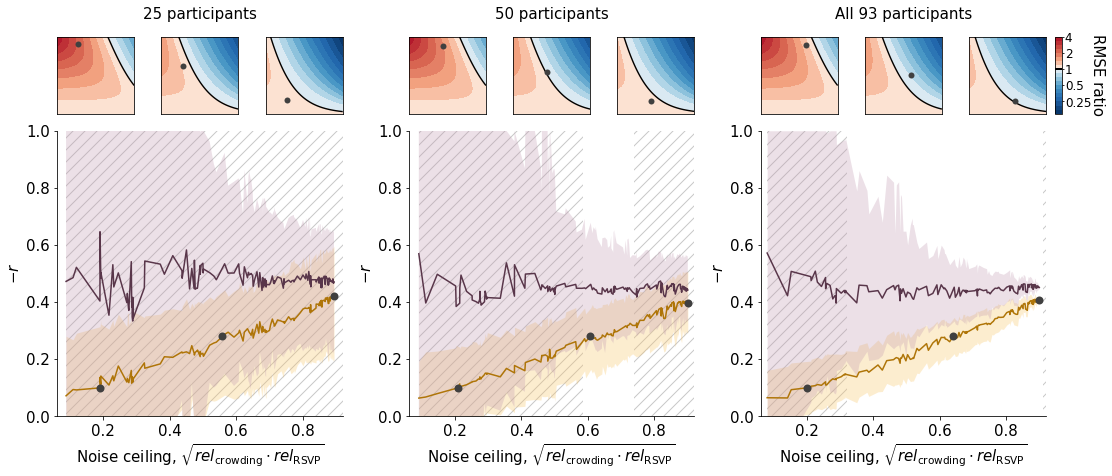

In [20]:
# panels: 25, 50 and all participants, with heatmap insets
panels = [(results_subset[n], f'{n} participants', n) for n in subset_sizes] + [(results, f'All {len(subjects)} participants', 'all')]
summaries = [summarize_draws(res) for res, _, _ in panels]
inset_points_per_panel = [inset_points(summary, inset_r) for summary in summaries]  # (noise ceilings, -r) per panel

# one color scale for every heatmap
z = [rmse_ratio_heatmap_data(r, method=inset_method, color_scale=inset_color_scale)[2]
     for _, rs in inset_points_per_panel for r in rs]
inset_colors = ratio_color_scale(min(float(v.min()) for v in z), max(float(v.max()) for v in z), inset_color_scale)

# ranges where r should not be corrected
no_correction = {}
for summary, (res, label, key) in zip(summaries, panels):
    if no_correction_method == 'closed_form':
        rho, no_correction[key] = closed_form_no_correction(summary, res['n_subjects'].iloc[0])
        print(f'{label}: rho fitted = {rho:.3f}; do not correct for noise ceiling in',
              ', '.join(f"[{'edge' if a is None else f'{a:.2f}'}, {'edge' if b is None else f'{b:.2f}'}]"
                        for a, b in no_correction[key]) or 'none')
    else:
        no_correction[key] = no_correction_ranges.get(key, ())

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels) + 1, 7))
for ax, summary, (res, label, key) in zip(axes, summaries, panels):
    plot_corr_vs_ceiling_median(summary, title=label, ax=ax, no_correction=no_correction[key])

# same x axis in every panel
x_min = min(ax.get_xlim()[0] for ax in axes)
x_max = max(ax.get_xlim()[1] for ax in axes)
for ax in axes:
    ax.set_xlim(x_min, x_max)
plt.tight_layout(rect=[0, 0, 0.93, 0.78])  # room above for the insets, and on the right for the colorbar

# insets go in after the layout is set
for ax, (ceilings, rs), (res, label, key) in zip(axes, inset_points_per_panel, panels):
    bounds = add_heatmap_insets(ax, res['n_subjects'].iloc[0], ceilings, rs, inset_colors, labels=inset_labels)
    ax.set_title(label, y=bounds[0][1] + bounds[0][3] + (0.1 if inset_labels else 0.04))

# colorbar beside the last heatmap, as tall as the heatmaps
x, y, width, height = bounds[-1]
cax = axes[-1].inset_axes([x + width + 0.03, y, 0.025, height])
cbar = add_ratio_colorbar(fig, cax, *inset_colors[1:], inset_color_scale, cbar_title=None,
                          fontsize=font_size, tick_fontsize=font_size*0.8)
cbar.set_label('RMSE ratio', rotation=270, labelpad=14, fontsize=font_size)
cbar.ax.tick_params(length=2, pad=1)
plt.show()